# Notebook E15: Valuasi Ekonomi Galat Rekonstruksi dengan Simulasi Sistem Tenaga Arab Saudi

**Proyek:** STMAC pada *cellular sheaf* untuk rekonstruksi irradiansi Arab Saudi
**Kaitan dengan naskah:** Bagian V-H (Persamaan 7), Bagian VI-B butir keempat dan kelima (*Limitations*)

## Tujuan

Reviewer SUSTAIN 2026 menilai model ekonomi naskah terlalu sederhana karena tidak memakai simulasi sistem tenaga. Persamaan (7) mengalikan RMSE rekonstruksi dengan tarif penalti 3 sampai 10 USD/MWh dari pasar AS dan Eropa. Arab Saudi tidak memiliki pasar *imbalance*; listrik dibeli oleh satu pembeli tunggal (SPPC) dan diseimbangkan oleh operator jaringan. Notebook ini mengganti tarif penalti dengan biaya yang benar-benar muncul di sistem Saudi: tambahan bahan bakar, *start-up*, dan beban tak terlayani ketika jadwal pembangkit disusun dengan estimasi PV yang salah.

Biaya dinilai sebagai biaya ekonomi bagi Kerajaan, yaitu *opportunity cost* bahan bakar. Minyak yang dibakar di pembangkit adalah minyak yang tidak diekspor, dan gas tambahan di pembangkit menggeser pembakaran minyak di pembangkit lain (Program *Liquid Displacement*). Dengan dasar itu, semua bahan bakar dinilai pada paritas ekspor minyak mentah per MMBtu.

## Masalah data dan cara kita menanganinya

Profil beban nasional per jam tidak dipublikasikan oleh Saudi Energy, NGSA, maupun WERA; tinjauan terbaru tentang penyimpanan energi di jaringan Saudi (Almohaimeed, *Applied Sciences* 16, 9569, 2026) juga menyatakan belum ada profil beban nasional per jam yang dapat dipakai. Kita menyusun estimasi yang paling mungkin dengan pencocokan momen bertingkat (*hierarchical moment matching*) terhadap statistik resmi, lalu memvalidasinya terhadap angka 2025 yang tidak dipakai dalam kalibrasi.

## Struktur notebook

1. Estimasi profil beban per jam 2025 dan validasinya.
2. Model sistem tenaga: armada pembangkit, bahan bakar, cadangan, dan validasi terhadap statistik 2025.
3. Estimasi daya PV dari rekonstruksi irradiansi (STMAC, MDV, GraphTRSS + MDV, TVGSR + MDV).
4. Simulasi penjadwalan dua tahap dan biaya galat.
5. Perbandingan dengan Persamaan (7), skenario harga bahan bakar, dan sensitivitas profil beban.

## 1. Lingkungan dan sumber data

| Data | Nilai | Sumber |
|---|---|---|
| Beban bulanan per wilayah (rata-rata, maksimum, minimum), 2009-2019 | GW | ECRA melalui portal data KAPSARC (`saudi-arabia-electricity-load-monthly-by-region`) |
| Beban puncak 2025 | 77.083 MW | GASTAT/KAPSARC (`electric-power-generation-capacity...`); MEES, 1 Mei 2026 |
| Penjualan per wilayah 2025 | Central 112,3; Western 107,33; Eastern 92,65; Southern 36,86 TWh | MEES, 1 Mei 2026 (Saudi Energy) |
| Energi tingkat pembangkitan 2025 | 237,82 + 191,32 = 429,14 TWh | Laporan Keberlanjutan Saudi Energy 2025 |
| Kurva harian tipikal | musim panas 13:00 ~52 GW, 19:00 ~51 GW; musim dingin 13:00 ~26,5 GW, 19:00 ~30 GW | ECRA 2015 dalam Krarti dkk., *Energies* 12(1), 87, 2019 |
| Efek Jumat dan durasi puncak | Jumat musim panas 10-15% lebih rendah; 3 GW teratas hanya 76 jam/tahun | ECRA 2019 dalam Alanazi dkk., *World Electr. Veh. J.* 13(5), 84, 2022 |
| Armada termal | SE: gas 23.551 MW, cair 33.097 MW; total terhubung 94,1 GW | Laporan Keberlanjutan SE 2025; SEC H1-2025 |
| Ketersediaan musim panas | CC 97,8%, siklus terbuka 96,5%, uap 93,3% | SEC H1-2025 |
| Efisiensi rata-rata | armada SE 38,15%; pembangkit gas 43,02% (bruto) | Laporan Keberlanjutan SE 2025 |
| Konsumsi minyak pembangkit 2025 | 991 ribu b/d | MEES, 1 Mei 2026 |
| Harga Brent | 69 USD/bbl (2025); 96 USD/bbl (proyeksi 2026) | EIA STEO, 6 Oktober 2026 |
| Nilai kesejahteraan minyak yang dihemat | 6 sampai 56 USD/bbl | Blazquez dkk., *Econ. Energy Environ. Policy* 8(2), 2019 |
| Biaya *start-up* | CC 55, uap 58, turbin gas 24 USD/MW (warm start, C&M) | Kumar dkk., NREL/SR-5500-55433, 2012 |
| Aturan cadangan | 3% beban + 5% PV | WWSIS, GE Energy, NREL/SR-550-47434, 2010 |

Notebook ini memerlukan modul E14 (`stmac_joint.py`, `stmac_rerun_utils.py`, `sky_tools.py`, `st_graph_recent.py`) dan tiga modul baru (`sa_load_model.py`, `sa_uc_model.py`, `sa_e15_runner.py`). Data listrik Saudi dibaca dari folder `data_sa/`.

In [1]:
import os, sys, json, time, warnings
from pathlib import Path
from multiprocessing import Pool

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
plt.rcParams.update({
    "font.size": 13, "axes.titlesize": 14, "axes.labelsize": 13.5,
    "xtick.labelsize": 12.5, "ytick.labelsize": 12.5, "legend.fontsize": 12,
    "figure.dpi": 110, "savefig.dpi": 400, "savefig.bbox": "tight",
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
})

HERE = Path.cwd().resolve()
for p in (HERE, HERE.parent, HERE / "notebooks"):
    if (p / "stmac_joint.py").exists() and str(p) not in sys.path:
        sys.path.insert(0, str(p))
    if (p / "sa_load_model.py").exists() and str(p) not in sys.path:
        sys.path.insert(0, str(p))

import stmac_joint as sj
import stmac_rerun_utils as ru
import st_graph_recent as gr
import sa_load_model as lm
import sa_uc_model as uc
import sa_e15_runner as er

DATA = ru.locate("data", "multistation_1999_cleaned.parquet")
ROOT = DATA.parent
RES = ROOT / "results"; RES.mkdir(exist_ok=True)
DSA = ru.locate("data_sa", "saudi-arabia-electricity-load-monthly-by-region.parquet")
WORK = RES / "E15_work"; WORK.mkdir(exist_ok=True)

N_PROC = max(1, min(4, (os.cpu_count() or 2)))
BRENT_2025, BRENT_2026 = 69.0, 96.0            # USD/bbl, EIA STEO 6 Okt 2026
FUEL_PRICE = BRENT_2025 / uc.MMBTU_PER_BBL      # USD/MMBtu, paritas ekspor minyak mentah
CAPS = [19.3, 40.0]                             # GW PV: beroperasi 2026; rencana 2027 / target NREP
CAP_VALID = 12.3                                # GW terbarukan terhubung akhir 2025
EPS, HD = 0.10, 4380.0                          # parameter Persamaan (7)


def idn(x, nd=1):
    s = f"{x:,.{nd}f}"
    return s.replace(",", "_").replace(".", ",").replace("_", ".")


print(f"DATA    : {DATA}\nDATA_SA : {DSA}\nRESULTS : {RES}\nproses paralel: {N_PROC}")
print(f"harga bahan bakar dasar {FUEL_PRICE:.2f} USD/MMBtu (Brent {BRENT_2025:.0f} USD/bbl)")

DATA    : /Users/user/Desktop/Proyek lomba paper/Project KFUPM/Final 5/stmac-demo 2/notebooks/data
DATA_SA : /Users/user/Desktop/Proyek lomba paper/Project KFUPM/Final 5/stmac-demo 2/notebooks/data_sa
RESULTS : /Users/user/Desktop/Proyek lomba paper/Project KFUPM/Final 5/stmac-demo 2/notebooks/results
proses paralel: 4
harga bahan bakar dasar 11.90 USD/MMBtu (Brent 69 USD/bbl)


## 2. Estimasi profil beban per jam

### 2.1 Metode

Kita membangun beban setiap wilayah $r$ pada jam $t$ (bulan $m$, hari $d$, jam lokal $h$) sebagai

$$L_r(t) = \bar{L}_r\, A_{r,m}\, \tilde D_r(d)\, F(d)\, \big[1 + \alpha_{r,m}\,(s_{m}(h) - 1)\big],$$

dengan langkah berikut:

1. $A_{r,m}$: rasio rata-rata bulan terhadap rata-rata tahunan, dirata-rata dari data ECRA 2015-2019. Baris data yang tidak konsisten (rata-rata di atas maksimum atau minimum di atas rata-rata) dibuang.
2. $\tilde D_r(d)$: lintasan harian hasil interpolasi PCHIP periodik melalui titik tengah bulan, dikalikan faktor cuaca harian log-normal $\exp(\sigma_d z_d)$ dengan $z_d$ proses AR(1) ($\phi = 0{,}7$; 70% komponen bersama antarwilayah). Statistik bulanan tidak memuat variasi antarhari, jadi komponen ini menggantikan variasi suhu harian yang tidak tersedia. Simpangannya $\sigma_d = \sigma_0 (0{,}5 + 0{,}5 w_m)$ lebih besar pada bulan pendinginan.
3. $F(d) = 0{,}875$ pada hari Jumat (titik tengah 10-15% dari ECRA 2019).
4. $s_m(h)$: templat harian yang mencampur templat musim dingin dan musim panas dengan bobot pendinginan $w_m$. Templat dijangkarkan pada kurva tipikal ECRA (rasio 19:00 terhadap 13:00 sebesar 51/52 pada musim panas dan 30/26,5 pada musim dingin), dengan minimum menjelang fajar mengikuti siklus suhu harian.
5. $\alpha_{r,m}$: amplitudo harian, dipilih per wilayah per bulan dengan kuadrat terkecil pada log rasio maksimum dan minimum bulanan terhadap data. Rata-rata bulanan dijaga tepat sama.
6. Wilayah dijumlahkan dengan bobot pangsa penjualan 2025, lalu diskalakan agar puncak tahunan = 77,083 GW.

Parameter bebas hanya $\sigma_0$. Kita memilih $\sigma_0$ agar energi tahunan rata-rata sama dengan 429,14 TWh (data 2025), lalu memeriksa hasilnya terhadap dua statistik yang tidak dipakai dalam kalibrasi: durasi 3 GW teratas (ECRA 2019: 76 jam) dan rasio beban musim panas terhadap musim dingin (sekitar dua kali lipat). Dari 30 realisasi acak, kita memilih realisasi yang paling dekat dengan energi 2025 dan durasi puncak 76 jam sebagai profil utama, dan memakai dua realisasi lain untuk uji sensitivitas.

Kalender jam memakai tahun 1999 agar beban dan irradiansi berada pada hari dan jam yang sama. Akhir pekan memakai aturan saat ini (Jumat). Profil ini adalah estimasi, bukan pengukuran; bagian validasi di bawah menunjukkan sejauh mana estimasi cocok dengan statistik resmi.

In [2]:
ST, DROPPED, NAT = lm.monthly_stats(DSA / "saudi-arabia-electricity-load-monthly-by-region.parquet")
HOURS = er.hourly_index(1999)
print("Baris data ECRA 2015-2019 yang dibuang karena tidak konsisten:")
print(DROPPED.to_string(index=False))
print("\nStatistik bulanan ternormalisasi (A = rata-rata bulan / rata-rata tahunan; rmax, rmin = maks, min / rata-rata bulan)")
print(ST.unstack(0).round(3).to_string())
ann = pd.read_parquet(DSA / "electric-power-generation-capacity-and-number-of-subscribers.parquet")
ann["year"] = pd.to_datetime(ann.year).dt.year
ann = ann.pivot_table(index="year", columns="indicators", values="value")
print("\nStatistik tahunan resmi (MW, ribu MWh):")
print(ann.tail(6).round(0).to_string())

Baris data ECRA 2015-2019 yang dibuang karena tidak konsisten:
      date  region  Average  Maximum  Minimum
2015-10-01 Eastern     11.5     16.9     11.9
2015-12-01 Eastern     13.4     12.1      9.7
2019-10-01 Eastern     15.2     14.7     13.2

Statistik bulanan ternormalisasi (A = rata-rata bulan / rata-rata tahunan; rmax, rmin = maks, min / rata-rata bulan)
stat         A                             rmax                             rmin                         
region Central Eastern Southern Western Central Eastern Southern Western Central Eastern Southern Western
month                                                                                                    
1        0.683   0.804    0.772   0.635   1.364   1.115    1.253   1.299   0.743   0.882    0.759   0.703
2        0.669   0.802    0.792   0.671   1.475   1.124    1.272   1.302   0.751   0.887    0.767   0.689
3        0.685   0.816    0.902   0.793   1.433   1.147    1.245   1.334   0.709   0.872    0.695   0.705

### 2.2 Kalibrasi variasi harian $\sigma_0$

Kita menjalankan model untuk tujuh nilai $\sigma_0$ dan 30 realisasi acak, lalu mencatat energi tahunan, faktor beban, durasi 3 GW teratas (relatif terhadap puncak: $3/62{,}1$ dari puncak), dan beban minimum. Sel berikut memerlukan sekitar satu menit.

In [3]:
SIG_OUT = WORK / "E15_sigma_scan.csv"
if SIG_OUT.exists():
    SIG = pd.read_csv(SIG_OUT)
else:
    rows = []
    for sg in [0.0, 0.05, 0.07, 0.08, 0.085, 0.09, 0.10]:
        for seed in range(30):
            Lx, inf = lm.national_hourly(ST, HOURS, sigma0=sg, seed=seed)
            rows.append(dict(sigma0=sg, seed=seed, energy_twh=inf["energy_twh"], load_factor=inf["load_factor"],
                             top_hours=lm.top_hours(Lx), min_gw=float(Lx.min())))
    SIG = pd.DataFrame(rows); SIG.to_csv(SIG_OUT, index=False)
SIG_SUM = SIG.groupby("sigma0")[["energy_twh", "load_factor", "top_hours", "min_gw"]].agg(["mean", "std"])
print(SIG_SUM.round(3).to_string())
E_TARGET = lm.ENERGY_2025_TWH
m_e = SIG.groupby("sigma0").energy_twh.mean()
SIGMA0 = float(np.interp(E_TARGET, m_e.values[::-1], m_e.index.values[::-1]))
SIGMA0 = float(min(m_e.index, key=lambda v: abs(v - SIGMA0)))
cand = SIG[SIG.sigma0 == SIGMA0].copy()
cand["dist"] = ((cand.energy_twh - E_TARGET) / 10) ** 2 + ((cand.top_hours - 76) / 50) ** 2
cand = cand.sort_values("dist")
LOAD_SEED = int(cand.seed.iloc[0]); ALT_SEEDS = [int(s) for s in cand.seed.iloc[1:3]]
print(f"\nsigma0 terpilih {SIGMA0} | realisasi utama seed {LOAD_SEED} | sensitivitas seed {ALT_SEEDS}")

       energy_twh         load_factor        top_hours          min_gw       
             mean     std        mean    std      mean     std    mean    std
sigma0                                                                       
0.000     470.433   0.000       0.697  0.000   817.000   0.000  28.619  0.000
0.050     448.550   7.405       0.664  0.011   140.200  89.354  27.388  0.471
0.070     438.180   9.703       0.649  0.014   106.300  70.054  26.766  0.640
0.080     432.336  10.574       0.640  0.016    97.600  64.063  26.395  0.721
0.085     429.214  11.054       0.636  0.016    93.267  59.332  26.195  0.756
0.090     426.033  11.546       0.631  0.017    90.033  56.351  25.988  0.792
0.100     419.405  12.506       0.621  0.019    87.367  54.468  25.559  0.857

sigma0 terpilih 0.085 | realisasi utama seed 7 | sensitivitas seed [15, 26]


In [4]:
print("INTERPRETASI KALIBRASI")
print("=" * 88)
s0 = SIG_SUM.loc[0.0]; ss = SIG_SUM.loc[SIGMA0]
print(f"- Tanpa variasi antarhari (sigma0 = 0), energi tahunan {idn(s0[('energy_twh', 'mean')])} TWh dan "
      f"durasi 3 GW teratas {idn(s0[('top_hours', 'mean')], 0)} jam. Profil terlalu datar di sekitar puncak "
      "karena setiap siang hari kerja musim panas mendekati puncak bulanan.")
print(f"- Pada sigma0 = {SIGMA0}, energi rata-rata {idn(ss[('energy_twh', 'mean')])} TWh (target 2025: "
      f"{idn(E_TARGET, 2)} TWh) dan durasi 3 GW teratas rata-rata {idn(ss[('top_hours', 'mean')], 0)} jam "
      f"(simpangan {idn(ss[('top_hours', 'std')], 0)} jam antarrealisasi; ECRA 2019: 76 jam).")
r0 = cand.iloc[0]
print(f"- Realisasi utama (seed {LOAD_SEED}): energi {idn(r0.energy_twh)} TWh, faktor beban "
      f"{idn(r0.load_factor, 3)}, durasi puncak {int(r0.top_hours)} jam, beban minimum {idn(r0.min_gw)} GW.")

INTERPRETASI KALIBRASI
- Tanpa variasi antarhari (sigma0 = 0), energi tahunan 470,4 TWh dan durasi 3 GW teratas 817 jam. Profil terlalu datar di sekitar puncak karena setiap siang hari kerja musim panas mendekati puncak bulanan.
- Pada sigma0 = 0.085, energi rata-rata 429,2 TWh (target 2025: 429,14 TWh) dan durasi 3 GW teratas rata-rata 93 jam (simpangan 59 jam antarrealisasi; ECRA 2019: 76 jam).
- Realisasi utama (seed 7): energi 428,7 TWh, faktor beban 0,635, durasi puncak 95 jam, beban minimum 26,3 GW.


### 2.3 Profil beban terpilih dan validasi

Tabel validasi membandingkan estimasi dengan statistik resmi. Kolom "dipakai dalam kalibrasi" menandai angka yang ikut menentukan parameter; angka lain adalah uji independen. Untuk minimum bulanan, data hanya memberi jumlah minimum wilayah yang tidak terjadi bersamaan, jadi angka itu adalah batas bawah bagi minimum nasional.

In [5]:
LOAD_GW, LINFO = lm.national_hourly(ST, HOURS, sigma0=SIGMA0, seed=LOAD_SEED)
np.save(WORK / "load_main_mw.npy", LOAD_GW * 1000.0)
for s in ALT_SEEDS:
    Lx, _ = lm.national_hourly(ST, HOURS, sigma0=SIGMA0, seed=s)
    np.save(WORK / f"load_seed{s}_mw.npy", Lx * 1000.0)
Ls = pd.Series(LOAD_GW, index=HOURS)

wk = Ls[~Ls.index.dayofweek.isin([4])]; fr = Ls[Ls.index.dayofweek == 4]
summer = Ls.index.month.isin([6, 7, 8]); winter = Ls.index.month.isin([12, 1, 2])
prof_s = wk[wk.index.month.isin([7, 8])].groupby(wk[wk.index.month.isin([7, 8])].index.hour).mean()
prof_w = wk[wk.index.month.isin([1, 2])].groupby(wk[wk.index.month.isin([1, 2])].index.hour).mean()
nat_n = NAT.copy(); nat_n["ann"] = nat_n.groupby(level=0).Average.transform("mean")
dn = nat_n[["Average", "Maximum", "Minimum"]].div(nat_n.ann, axis=0).groupby(level=1).mean()
mm = Ls.resample("MS").agg(["mean", "max", "min"]) / Ls.mean()
VAL = pd.DataFrame([
    ("Puncak tahunan (GW)", Ls.max(), 77.083, "ya"),
    ("Energi tahunan (TWh)", Ls.sum() / 1000, E_TARGET, "ya (sigma0)"),
    ("Faktor beban", Ls.mean() / Ls.max(), E_TARGET * 1000 / 8760 / 77.083, "turunan"),
    ("Jam dengan beban > puncak - 3/62,1 puncak", lm.top_hours(LOAD_GW), 76, "tidak"),
    ("Rasio rata-rata Jun-Agu / Des-Feb", Ls[summer].mean() / Ls[winter].mean(), 2.0, "tidak (\"hampir dua kali\")"),
    ("Rasio Jumat / hari kerja, Jul-Agu", fr[fr.index.month.isin([7, 8])].mean() / wk[wk.index.month.isin([7, 8])].mean(), 0.875, "ya (konstruksi)"),
    ("Musim panas: 19:00 / 13:00", prof_s[19] / prof_s[13], 51 / 52, "templat"),
    ("Musim dingin: 19:00 / 13:00", prof_w[19] / prof_w[13], 30 / 26.5, "templat"),
    ("Korelasi maks bulanan/rata-rata tahunan vs data", np.corrcoef(mm["max"].values, dn.Maximum.values)[0, 1], 1.0, "tidak"),
], columns=["indikator", "estimasi", "acuan", "dipakai dalam kalibrasi"])
ru.atomic_csv(VAL, RES / "E15_load_validation.csv")
MON = pd.DataFrame({"est_rata": mm["mean"].values, "data_rata": dn.Average.values,
                    "est_maks": mm["max"].values, "data_jumlah_maks": dn.Maximum.values,
                    "est_min": mm["min"].values, "data_jumlah_min": dn.Minimum.values},
                   index=[f"{m:02d}" for m in range(1, 13)])
ru.atomic_csv(MON.reset_index().rename(columns={"index": "bulan"}), RES / "E15_load_monthly_check.csv")
# ekspor profil beban per jam: kalender jam 1999 (sama dengan irradiansi), tingkat beban 2025
EXP = pd.DataFrame({"jam_ke": np.arange(len(HOURS)), "bulan": HOURS.month, "hari": HOURS.day,
                    "jam_lokal": HOURS.hour, "jumat": (HOURS.dayofweek == 4).astype(int),
                    "beban_nasional_gw": LOAD_GW})
for r_ in lm.REGIONS:
    EXP[f"beban_{r_.lower()}_gw"] = LINFO["regional"][r_]
for s in ALT_SEEDS:
    EXP[f"beban_nasional_gw_seed{s}"] = np.load(WORK / f"load_seed{s}_mw.npy") / 1000.0
ru.atomic_csv(EXP, RES / "E15_hourly_load_estimate_2025.csv")
print(VAL.to_string(index=False, float_format=lambda v: f"{v:9.3f}"))
print("\nPerbandingan bulanan (dibagi rata-rata tahunan)")
print(MON.round(3).to_string())

                                      indikator  estimasi     acuan   dipakai dalam kalibrasi
                            Puncak tahunan (GW)    77.083    77.083                        ya
                           Energi tahunan (TWh)   428.721   429.140               ya (sigma0)
                                   Faktor beban     0.635     0.636                   turunan
      Jam dengan beban > puncak - 3/62,1 puncak    95.000    76.000                     tidak
              Rasio rata-rata Jun-Agu / Des-Feb     1.799     2.000 tidak ("hampir dua kali")
              Rasio Jumat / hari kerja, Jul-Agu     0.884     0.875           ya (konstruksi)
                     Musim panas: 19:00 / 13:00     0.996     0.981                   templat
                    Musim dingin: 19:00 / 13:00     1.093     1.132                   templat
Korelasi maks bulanan/rata-rata tahunan vs data     0.960     1.000                     tidak

Perbandingan bulanan (dibagi rata-rata tahunan)
    est_rat

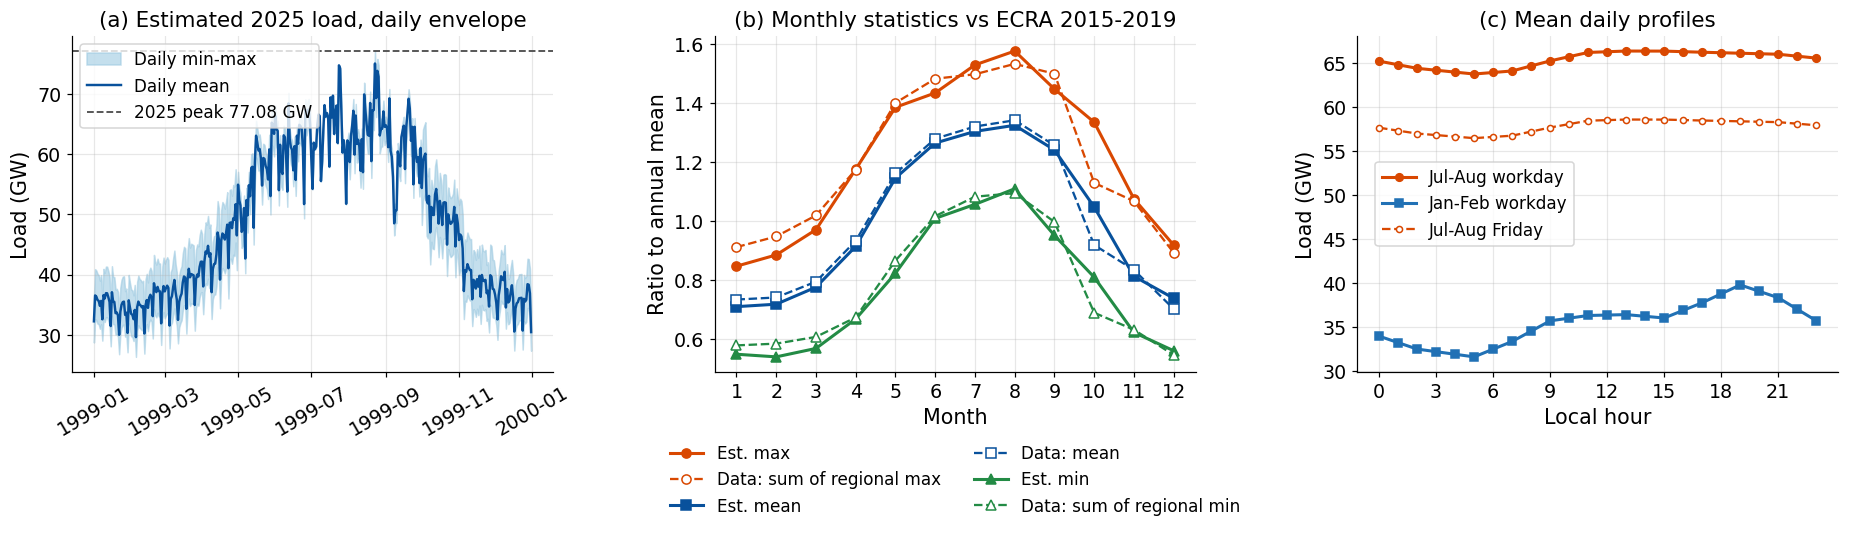

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
ax = axes[0]
dmax = Ls.resample("D").max(); dmean = Ls.resample("D").mean(); dmin = Ls.resample("D").min()
ax.fill_between(dmax.index, dmin, dmax, color="#9ecae1", alpha=0.6, label="Daily min-max")
ax.plot(dmean.index, dmean, color="#08519c", lw=1.6, label="Daily mean")
ax.axhline(77.083, color="0.3", ls="--", lw=1.2, label="2025 peak 77.08 GW")
ax.set_ylabel("Load (GW)"); ax.set_title("(a) Estimated 2025 load, daily envelope")
ax.legend(loc="upper left", frameon=True, fontsize=11)
ax.tick_params(axis="x", rotation=30)
ax = axes[1]
x = np.arange(1, 13)
ax.plot(x, MON.est_maks, "o-", color="#d94801", lw=2, ms=6, label="Est. max")
ax.plot(x, MON.data_jumlah_maks, "o--", color="#d94801", lw=1.5, ms=6, mfc="white", label="Data: sum of regional max")
ax.plot(x, MON.est_rata, "s-", color="#08519c", lw=2, ms=6, label="Est. mean")
ax.plot(x, MON.data_rata, "s--", color="#08519c", lw=1.5, ms=6, mfc="white", label="Data: mean")
ax.plot(x, MON.est_min, "^-", color="#238b45", lw=2, ms=6, label="Est. min")
ax.plot(x, MON.data_jumlah_min, "^--", color="#238b45", lw=1.5, ms=6, mfc="white", label="Data: sum of regional min")
ax.set_xticks(x); ax.set_xlabel("Month"); ax.set_ylabel("Ratio to annual mean")
ax.set_title("(b) Monthly statistics vs ECRA 2015-2019")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), fontsize=11, ncol=2, frameon=False)
ax = axes[2]
ax.plot(range(24), prof_s.values, "o-", color="#d94801", lw=2, ms=5, label="Jul-Aug workday")
ax.plot(range(24), prof_w.values, "s-", color="#2171b5", lw=2, ms=5, label="Jan-Feb workday")
fs = fr[fr.index.month.isin([7, 8])]
ax.plot(range(24), fs.groupby(fs.index.hour).mean().values, "o--", color="#d94801", lw=1.5, ms=4, mfc="white", label="Jul-Aug Friday")
ax.set_xlabel("Local hour"); ax.set_ylabel("Load (GW)"); ax.set_xticks(range(0, 24, 3))
ax.set_title("(c) Mean daily profiles")
ax.legend(loc="center left", bbox_to_anchor=(0.02, 0.5), frameon=True, fontsize=11)
fig.tight_layout()
fig.savefig(RES / "E15_load_profile.png")
plt.show()

In [7]:
print("INTERPRETASI PROFIL BEBAN")
print("=" * 88)
v = VAL.set_index("indikator")
print(f"- Puncak {idn(v.loc['Puncak tahunan (GW)', 'estimasi'], 2)} GW dan energi "
      f"{idn(v.loc['Energi tahunan (TWh)', 'estimasi'])} TWh (data 2025: 429,1 TWh); faktor beban "
      f"{idn(v.loc['Faktor beban', 'estimasi'], 3)}.")
th = v.loc["Jam dengan beban > puncak - 3/62,1 puncak", "estimasi"]
print(f"- Durasi 3 GW teratas {idn(th, 0)} jam terhadap 76 jam pada ECRA 2019 (uji independen).")
print(f"- Rasio musim panas terhadap musim dingin {idn(v.loc['Rasio rata-rata Jun-Agu / Des-Feb', 'estimasi'], 2)} "
      "(ECRA 2019: hampir dua kali).")
dmx = (MON.est_maks - MON.data_jumlah_maks)
print(f"- Maksimum bulanan estimasi berselisih {idn(dmx.min(), 3)} sampai {idn(dmx.max(), 3)} (rasio terhadap "
      "rata-rata tahunan) dari jumlah maksimum wilayah; jumlah itu adalah batas atas bagi maksimum nasional.")
below = MON.index[MON.est_min < MON.data_jumlah_min].tolist()
print(f"- Minimum bulanan estimasi berada di bawah jumlah minimum wilayah (batas bawah) pada bulan {', '.join(below) or 'tidak ada'}; "
      "malam hari pada bulan-bulan itu kemungkinan sedikit terlalu rendah.")
print(f"- Pada hari kerja Juli-Agustus beban siang dan malam hampir sama tinggi (19:00/13:00 = "
      f"{idn(v.loc['Musim panas: 19:00 / 13:00', 'estimasi'], 3)}); pada musim dingin puncak terjadi malam hari "
      f"(19:00/13:00 = {idn(v.loc['Musim dingin: 19:00 / 13:00', 'estimasi'], 3)}).")

INTERPRETASI PROFIL BEBAN
- Puncak 77,08 GW dan energi 428,7 TWh (data 2025: 429,1 TWh); faktor beban 0,635.
- Durasi 3 GW teratas 95 jam terhadap 76 jam pada ECRA 2019 (uji independen).
- Rasio musim panas terhadap musim dingin 1,80 (ECRA 2019: hampir dua kali).
- Maksimum bulanan estimasi berselisih -0,065 sampai 0,205 (rasio terhadap rata-rata tahunan) dari jumlah maksimum wilayah; jumlah itu adalah batas atas bagi maksimum nasional.
- Minimum bulanan estimasi berada di bawah jumlah minimum wilayah (batas bawah) pada bulan 01, 02, 03, 04, 05, 06, 07, 09, 11; malam hari pada bulan-bulan itu kemungkinan sedikit terlalu rendah.
- Pada hari kerja Juli-Agustus beban siang dan malam hampir sama tinggi (19:00/13:00 = 0,996); pada musim dingin puncak terjadi malam hari (19:00/13:00 = 1,093).


## 3. Model sistem tenaga dan validasinya

### 3.1 Struktur model

Model berbentuk simpul tunggal dengan resolusi per jam. Pembangkit termal dikelompokkan ke empat kluster (*clustered unit commitment*). Jumlah unit CCGT dan uap yang menyala adalah variabel integer; komitmen OCGT dan GT yang berukuran kecil dan cepat diperlakukan kontinu (relaksasi kluster). Selisih biaya harian antarmetode berorde ratusan sampai ribuan USD, jauh di bawah celah optimalitas bawaan MILP (1e-4 dari biaya harian sekitar 100 juta USD), jadi kita memakai celah 1e-8. Relaksasi unit cepat membuat celah seketat itu dapat dicapai dalam hitungan milidetik per hari; pada uji empat hari, hasilnya berbeda kurang dari 2% dari formulasi integer penuh.

| Kluster | Bahan bakar | Terpasang (MW) | Unit (MW) | Efisiensi | $P_{\min}$ | Ketersediaan | Start-up (USD/MW) | Commit ulang real time |
|---|---|---|---|---|---|---|---|---|
| CCGT | gas | 26.000 | 500 | 50% | 50% | 97,8% | 55 | tidak |
| OCGT | gas | 20.000 | 150 | 32% | 30% | 96,5% | 24 | ya |
| Uap | minyak mentah/HFO | 33.000 | 400 | 35% | 40% | 93,3% | 58 | tidak |
| GT | minyak/diesel | 7.000 | 100 | 28% | 30% | 96,5% | 24 | ya |

Total kapasitas termal 86 GW, konsisten dengan 94,1 GW kapasitas terhubung (SEC H1-2025) dikurangi kapasitas terbarukan, serta dengan kapasitas aktual SE (gas 23,6 GW, cair 33,1 GW) ditambah IPP. Pembagian teknologi di dalam tiap kelompok bahan bakar dan efisiensi per kluster adalah asumsi; kita memeriksanya terhadap efisiensi rata-rata dan konsumsi minyak 2025.

**Tahap 1, penjadwalan intrahari.** Untuk setiap hari, MILP meminimumkan biaya bahan bakar dan *start-up* dengan estimasi PV $\hat P^{PV}_t$. Cadangan berputar mengikuti aturan 3% beban + 5% PV (WWSIS). Pada varian cadangan berbasis ketidakpastian, saat sensor padam cadangan ditambah $1{,}645\,\sigma_t$, dengan $\sigma_t$ simpangan baku galat estimasi PV dari RMSE metode pada panjang blok yang sama (E14).

**Tahap 2, real time.** Komitmen CCGT dan uap dikunci dari tahap 1. OCGT dan GT boleh dinyalakan atau dimatikan. Dispatch dioptimalkan ulang terhadap PV aktual; PV boleh dibatasi tanpa biaya, beban yang tidak terlayani dikenai VOLL 10.000 USD/MWh.

**Biaya galat** suatu metode = biaya tahap 2 metode itu dikurangi biaya tahap 2 dengan informasi PV sempurna, pada hari yang sama dan keadaan komitmen awal yang sama. Hari tanpa galat estimasi tidak dihitung ulang.

**Harga bahan bakar.** Semua bahan bakar dinilai sama per MMBtu pada paritas ekspor minyak mentah: 69 USD/bbl (rata-rata Brent 2025) dibagi 5,8 MMBtu/bbl = 11,9 USD/MMBtu. Dengan harga seragam, urutan merit hanya ditentukan efisiensi, dan biaya bahan bakar berbanding lurus dengan harga minyak. Skenario 96 USD/bbl (proyeksi 2026 setelah gangguan Selat Hormuz) dan 6 sampai 56 USD/bbl (nilai kesejahteraan per barel yang dihemat, Blazquez dkk. 2019) dihitung dengan menskalakan komponen bahan bakar.

**PV.** Kapasitas PV dibagi rata ke 11 lokasi stasiun. Daya per jam = kapasitas x min(1; 0,85 x GHI/1000); faktor kapasitasnya 0,21, sama dengan asumsi E6.

### 3.2 Validasi terhadap statistik 2025

Kita menjalankan satu tahun penuh dengan informasi sempurna dan 12,3 GW PV (kapasitas terbarukan terhubung akhir 2025), lalu membandingkan hasilnya dengan statistik 2025. Sel ini memerlukan sekitar satu sampai dua menit.

In [8]:
FLEET = uc.default_fleet_2025()
print(pd.DataFrame([dict(kluster=c.name, bahan_bakar=c.fuel, terpasang_mw=c.installed_mw, unit_mw=c.unit_mw,
                         jumlah_unit=c.n_units, efisiensi=c.efficiency, pmin=c.pmin_frac, ketersediaan=c.availability,
                         heat_rate_mmbtu_mwh=round(c.heat_rate, 3), startup_usd_mw=c.start_cost_per_mw, cepat=c.fast)
                    for c in FLEET]).to_string(index=False))

ST_JSON = json.load(open(DATA / "stations.json")); CODES = list(ST_JSON)
LAT = np.array([ST_JSON[c]["lat"] for c in CODES]); LON = np.array([ST_JSON[c]["lon"] for c in CODES])
multi = pd.read_parquet(DATA / "multistation_1999_cleaned.parquet")[CODES]
U_ALL = multi.to_numpy().T.astype(float); N, T = U_ALL.shape; IDX = multi.index


def to_hourly(X):
    return (pd.DataFrame(X.T, index=IDX, columns=CODES).resample("1h").mean().reindex(HOURS)
            .interpolate(limit_direction="both").values)


UP = er.solar_up(HOURS, LAT, LON, 3.0)
G_TRUE = er.postprocess(to_hourly(U_ALL), UP)
np.save(WORK / "ghi_true_h.npy", G_TRUE); np.save(WORK / "sun_up_h.npy", UP)
print(f"\nFaktor kapasitas PV dari GHI 1999: {er.pv_mw(G_TRUE, 1.0).sum(1).mean() / 1000:.3f}")


def base_params(cap, load_path=WORK / "load_main_mw.npy", tag="main"):
    return dict(method="perfect", cap_gw=cap, fuel_price=FUEL_PRICE, load_path=str(load_path),
                true_path=str(WORK / "ghi_true_h.npy"), up_path=str(WORK / "sun_up_h.npy"),
                recon_path=None, days_out=str(WORK / f"days_perfect_{tag}_{cap}.csv"),
                ustart_out=str(WORK / f"ustart_perfect_{tag}_{cap}.npy"))


VAL_OUT = RES / "E15_system_validation_raw.csv"
if VAL_OUT.exists():
    VR = pd.read_csv(VAL_OUT).iloc[0].to_dict()
else:
    VR = er.run_case(("valid", base_params(CAP_VALID, tag="valid")))
    pd.DataFrame([VR]).to_csv(VAL_OUT, index=False)
fuel = np.array([VR[f"fuel_mmbtu_{k}"] for k in range(4)]); gen = np.array([VR[f"gen_mwh_{k}"] for k in range(4)])
liq = np.array([c.fuel == "liquid" for c in FLEET])
SYSVAL = pd.DataFrame([
    ("Pembangkitan termal (TWh)", gen.sum() / 1e6, 429.14 - 24.74, "Laporan SE 2025 (total dikurangi terbarukan 24,74 TWh)"),
    ("Pembangkitan PV terpakai (TWh)", VR["pv_used_mwh"] / 1e6, 24.74, "terbarukan terkirim 2025 (termasuk angin, kapasitas bertambah sepanjang tahun)"),
    ("Efisiensi rata-rata termal (%)", 100 * gen.sum() * uc.MWH_TO_MMBTU / fuel.sum(), 38.15, "armada SE, bruto"),
    ("Pangsa pembangkitan bahan bakar cair (%)", 100 * gen[liq].sum() / gen.sum(), 100 * 123.38 / 237.82, "armada SE saja"),
    ("Konsumsi bahan bakar cair (ribu b/d setara minyak)", fuel[liq].sum() / uc.MMBTU_PER_BBL / 365 / 1000, 991.0, "MEES: crude + fuel oil, termasuk non-SE"),
    ("Beban tak terlayani (GWh)", VR["shed_mwh"] / 1000, 0.0, "-"),
], columns=["indikator", "model", "acuan 2025", "catatan"])
ru.atomic_csv(SYSVAL, RES / "E15_system_validation.csv")
print(SYSVAL.to_string(index=False, float_format=lambda v: f"{v:9.2f}"))

     kluster bahan_bakar  terpasang_mw  unit_mw  jumlah_unit  efisiensi  pmin  ketersediaan  heat_rate_mmbtu_mwh  startup_usd_mw  cepat
  CCGT (gas)         gas         26000      500           52       0.50   0.5         0.978                6.824            55.0  False
  OCGT (gas)         gas         20000      150          133       0.32   0.3         0.965               10.663            24.0   True
Uap (minyak)      liquid         33000      400           82       0.35   0.4         0.933                9.749            58.0  False
 GT (minyak)      liquid          7000      100           70       0.28   0.3         0.965               12.186            24.0   True

Faktor kapasitas PV dari GHI 1999: 0.211
                                         indikator     model  acuan 2025                                                                        catatan
                         Pembangkitan termal (TWh)    405.98      404.40                         Laporan SE 2025 (total dikura

In [9]:
print("INTERPRETASI VALIDASI SISTEM")
print("=" * 88)
sv = SYSVAL.set_index("indikator")
for k in sv.index:
    m, a = sv.loc[k, "model"], sv.loc[k, "acuan 2025"]
    rel = "" if a == 0 else f" ({idn(100 * (m / a - 1), 0)}% terhadap acuan)"
    print(f"- {k}: model {idn(m, 2)}, acuan {idn(a, 2)}{rel}.")
print("- Model memakai urutan merit berdasarkan efisiensi pada harga bahan bakar seragam. Dalam praktik, pasokan gas "
      "terbatas dan sebagian unit gas tidak terhubung ke jaringan gas, jadi pangsa minyak aktual lebih tinggi daripada "
      "model. Selisih ini menggeser tingkat biaya total, tetapi biaya galat yang kita hitung adalah selisih antara dua "
      "jadwal pada sistem yang sama.")

INTERPRETASI VALIDASI SISTEM
- Pembangkitan termal (TWh): model 405,98, acuan 404,40 (0% terhadap acuan).
- Pembangkitan PV terpakai (TWh): model 22,74, acuan 24,74 (-8% terhadap acuan).
- Efisiensi rata-rata termal (%): model 41,70, acuan 38,15 (9% terhadap acuan).
- Pangsa pembangkitan bahan bakar cair (%): model 41,20, acuan 51,88 (-21% terhadap acuan).
- Konsumsi bahan bakar cair (ribu b/d setara minyak): model 770,20, acuan 991,00 (-22% terhadap acuan).
- Beban tak terlayani (GWh): model 0,00, acuan 0,00.
- Model memakai urutan merit berdasarkan efisiensi pada harga bahan bakar seragam. Dalam praktik, pasokan gas terbatas dan sebagian unit gas tidak terhubung ke jaringan gas, jadi pangsa minyak aktual lebih tinggi daripada model. Selisih ini menggeser tingkat biaya total, tetapi biaya galat yang kita hitung adalah selisih antara dua jadwal pada sistem yang sama.


## 4. Estimasi PV dari rekonstruksi irradiansi

Untuk setiap *mask* E9J (10% sel per stasiun hilang dalam blok), operator mengestimasi daya PV di lokasi yang sensornya padam dari rekonstruksi; lokasi lain memakai pengukuran. Kita memakai empat metode dengan bobot yang sama seperti E12 dan E14:

- STMAC ($r = 10^3$, $g = 3$, sheaf longitude);
- MDV (klimatologi stasiun);
- GraphTRSS + MDV ($\nu = 1$, $\varepsilon = 1$, $\beta = 1$), pembanding terbaik E14;
- TVGSR + MDV ($\nu = 10$).

*Mask* yang dipakai: *seed* 0 untuk ketujuh panjang blok, ditambah *seed* 1 untuk blok 6 jam dan 3 hari sebagai pemeriksaan ulang. Semua estimasi diperlakukan sama: nilai negatif dipotong nol dan GHI malam hari diset nol.

In [10]:
RMSE_E14 = pd.read_csv(RES / "E14_summary_all.csv").set_index("label")
MKEY = {"stmac": "anomaly", "mdv": "climatology", "graphtrss_mdv": "graphtrss_mdv", "tvgsr_mdv": "tvgsr_mdv"}
MNAME = {"stmac": "STMAC", "mdv": "MDV", "graphtrss_mdv": "GraphTRSS + MDV", "tvgsr_mdv": "TVGSR + MDV"}
L_G = np.load(DATA / "graph_L.npy"); L_TIME = sj.build_temporal_smoothness(T)
DELTA = (LON - LON.mean()) / 15 * 60 / 5
MASKS = [(0, bl) for bl, _ in sj.BLOCK_SPECS] + [(1, 72), (1, 864)]
LAB = dict(sj.BLOCK_SPECS)
err_rows = []
for seed, bl in MASKS:
    f = WORK / f"recon_seed{seed}_bl{bl}.npz"
    if not f.exists():
        m, _ = sj.build_block_mask(N, T, bl, 0.10, seed=seed)
        Cm = ru.mdv_field(U_ALL, m, IDX, 15)
        rec = {"stmac": sj.stmac_joint(U_ALL, m, L_G, L_TIME, DELTA, None, 1000.0, 1.0, ridge=3.0, prior=Cm),
               "mdv": np.where(m, U_ALL, Cm),
               "graphtrss_mdv": gr.graphtrss(U_ALL, m, L_G, 1.0, 1.0, 1.0, prior=Cm),
               "tvgsr_mdv": gr.tvgsr(U_ALL, m, L_G, 10.0, prior=Cm)}
        out = {k: to_hourly(np.where(m, U_ALL, v)) for k, v in rec.items()}
        out["missfrac"] = to_hourly((~m).astype(float))
        np.savez_compressed(f, **out)
    z = np.load(f)
    for k in MNAME:
        Gh = er.postprocess(z[k], UP)
        d = (Gh - G_TRUE)[UP]
        err_rows.append(dict(seed=seed, block_len=bl, label=LAB[bl], method=k,
                             rmse_hourly=float(np.sqrt(np.mean(d ** 2))), mae_hourly=float(np.mean(np.abs(d))),
                             bias_hourly=float(np.mean(d)), missfrac=float(z["missfrac"].mean())))
ERR = pd.DataFrame(err_rows)
ru.atomic_csv(ERR, RES / "E15_hourly_estimate_errors.csv")
print("RMSE per jam GHI estimasi pada jam siang (W/m2, termasuk jam tanpa sel hilang), seed 0")
print(ERR[ERR.seed == 0].pivot(index="label", columns="method", values="rmse_hourly")
      .loc[[l for _, l in sj.BLOCK_SPECS]].rename(columns=MNAME).round(2).to_string())

RMSE per jam GHI estimasi pada jam siang (W/m2, termasuk jam tanpa sel hilang), seed 0
method  GraphTRSS + MDV    MDV  STMAC  TVGSR + MDV
label                                             
30 min            10.23  29.77  14.46        11.51
2 h               16.40  37.34  31.04        18.56
6 h               27.60  37.40  35.42        29.74
12 h              34.59  39.76  38.16        36.70
1 day             38.97  41.90  41.05        41.74
3 day             44.21  43.39  42.80        46.19
7 day             47.17  45.07  43.97        52.04


method  GraphTRSS + MDV    MDV  STMAC  TVGSR + MDV
label                                             
30 min            10.23  29.77  14.46        11.51
2 h               16.40  37.34  31.04        18.56
6 h               27.60  37.40  35.42        29.74
12 h              34.59  39.76  38.16        36.70
1 day             38.97  41.90  41.05        41.74
3 day             44.21  43.39  42.80        46.19
7 day             47.17  45.07  43.97        52.04


## 5. Simulasi penjadwalan dua tahap

Kasus yang dijalankan:

- informasi sempurna untuk setiap kapasitas PV (19,3 GW dan 40 GW) dengan profil beban utama;
- empat metode x sembilan *mask* x dua kapasitas PV dengan aturan cadangan 3+5;
- empat metode x sembilan *mask* pada 40 GW dengan cadangan berbasis ketidakpastian;
- sensitivitas profil beban: dua realisasi beban lain, 40 GW, blok 1 hari, aturan 3+5.

Setiap kasus disimpan ke `results/E15_runs.csv` begitu selesai, jadi sel ini dapat dijalankan ulang dan melanjutkan dari kasus terakhir. Waktu total sekitar 30 sampai 60 menit, bergantung pada jumlah inti CPU.

In [11]:
RUNS_OUT = RES / "E15_runs.csv"
done = set(pd.read_csv(RUNS_OUT).key) if RUNS_OUT.exists() else set()


def save_row(row):
    df = pd.DataFrame([row])
    if RUNS_OUT.exists():
        df = pd.concat([pd.read_csv(RUNS_OUT), df], ignore_index=True)
    ru.atomic_csv(df, RUNS_OUT)


perfect = []
for cap in CAPS:
    perfect.append((f"perfect|main|{cap}", base_params(cap)))
for s in ALT_SEEDS:
    perfect.append((f"perfect|seed{s}|40.0", base_params(40.0, WORK / f"load_seed{s}_mw.npy", tag=f"seed{s}")))
todo = [c for c in perfect if c[0] not in done]
t0 = time.time()
with Pool(N_PROC) as pool:
    for row in pool.imap_unordered(er.run_case, todo):
        save_row(row); print(f"{row['key']:<28s} {row['sec']:6.0f} s", flush=True)


def method_params(method, seed, bl, cap, reserve, tag="main"):
    lab = LAB[bl]
    p = dict(method=method, cap_gw=cap, fuel_price=FUEL_PRICE, reserve=reserve,
             rmse=float(RMSE_E14.loc[lab, MKEY[method]]),
             load_path=str(WORK / ("load_main_mw.npy" if tag == "main" else f"load_{tag}_mw.npy")),
             true_path=str(WORK / "ghi_true_h.npy"), up_path=str(WORK / "sun_up_h.npy"),
             recon_path=str(WORK / f"recon_seed{seed}_bl{bl}.npz"),
             days_base=str(WORK / f"days_perfect_{tag}_{cap}.csv"),
             ustart_base=str(WORK / f"ustart_perfect_{tag}_{cap}.npy"))
    return (f"{method}|{tag}|{cap}|{reserve}|s{seed}|{bl}", p)


cases = []
for cap in CAPS:
    for seed, bl in MASKS:
        for mth in MNAME:
            cases.append(method_params(mth, seed, bl, cap, "rule"))
for seed, bl in MASKS:
    for mth in MNAME:
        cases.append(method_params(mth, seed, bl, 40.0, "uncertainty"))
for s in ALT_SEEDS:
    for mth in MNAME:
        cases.append(method_params(mth, 0, 288, 40.0, "rule", tag=f"seed{s}"))
todo = [c for c in cases if c[0] not in done]
print(f"{len(cases)} kasus metode, {len(todo)} belum dijalankan")
with Pool(N_PROC) as pool:
    for i, row in enumerate(pool.imap_unordered(er.run_case, todo)):
        save_row(row)
        if i % 8 == 0:
            print(f"{i + 1:3d}/{len(todo)} {row['key']:<44s} {row['sec']:5.0f} s | {(time.time() - t0) / 60:5.1f} menit", flush=True)
RUNS = pd.read_csv(RUNS_OUT)
print(f"{len(RUNS)} baris hasil")

perfect|main|19.3                66 s
perfect|seed15|40.0              90 s
perfect|main|40.0                90 s
perfect|seed26|40.0              90 s
116 kasus metode, 116 belum dijalankan
  1/116 graphtrss_mdv|main|19.3|rule|s0|6               75 s |   2.8 menit
  9/116 stmac|main|19.3|rule|s0|72                      39 s |   4.4 menit
 17/116 stmac|main|19.3|rule|s0|288                     31 s |   5.5 menit
 25/116 stmac|main|19.3|rule|s0|2016                    29 s |   6.5 menit
 33/116 stmac|main|19.3|rule|s1|864                     33 s |   7.7 menit
 41/116 stmac|main|40.0|rule|s0|24                      53 s |   9.5 menit
 49/116 stmac|main|40.0|rule|s0|144                     51 s |  11.2 menit
 57/116 stmac|main|40.0|rule|s0|864                     39 s |  12.5 menit
 65/116 stmac|main|40.0|rule|s1|72                      53 s |  14.1 menit
 73/116 stmac|main|40.0|uncertainty|s0|6                53 s |  15.6 menit
 81/116 stmac|main|40.0|uncertainty|s0|72               52 

120 baris hasil


## 6. Hasil: biaya galat per tahun

Untuk setiap kasus kita menghitung:

- $\Delta C$: tambahan biaya tahunan (bahan bakar + *start-up* + VOLL) terhadap informasi sempurna, juta USD/tahun pada 69 USD/bbl;
- $\Delta F$: tambahan bahan bakar dalam ribu barel setara minyak per tahun;
- tarif efektif: $\Delta C$ dibagi galat absolut estimasi PV (MWh), dapat dibandingkan langsung dengan tarif 3 sampai 10 USD/MWh di Persamaan (7);
- biaya menurut Persamaan (7) untuk RMSE metode yang sama (E14) pada kapasitas yang sama.

In [12]:
R = RUNS[~RUNS.key.str.startswith("perfect")].copy()
parts = R.key.str.split("|", expand=True)
R["method"], R["tag"], R["cap"], R["reserve"], R["seed"], R["block_len"] = (
    parts[0], parts[1], parts[2].astype(float), parts[3], parts[4].str[1:].astype(int), parts[5].astype(int))
R["label"] = R.block_len.map(LAB)
R["d_cost_musd"] = R.d_total_cost / 1e6
R["d_fuel_kbbl"] = R.d_fuel_mmbtu / uc.MMBTU_PER_BBL / 1000
R["eff_rate"] = R.d_total_cost / R.abs_err_mwh
R["rmse_e14"] = [float(RMSE_E14.loc[l, MKEY[m]]) for l, m in zip(R.label, R.method)]
R["eq7_3_musd"] = R.cap * R.rmse_e14 / 1000 * EPS * HD * 3.0 / 1e3
R["eq7_10_musd"] = R.cap * R.rmse_e14 / 1000 * EPS * HD * 10.0 / 1e3
ru.atomic_csv(R, RES / "E15_cases.csv")
main = R[(R.tag == "main") & (R.seed == 0)]
order = [l for _, l in sj.BLOCK_SPECS]
for cap in CAPS:
    for res in ["rule", "uncertainty"]:
        sub = main[(main.cap == cap) & (main.reserve == res)]
        if sub.empty:
            continue
        print(f"\nPV {cap} GW, cadangan {res}: tambahan biaya (juta USD/tahun, 69 USD/bbl)")
        print(sub.pivot(index="label", columns="method", values="d_cost_musd").loc[order]
              .rename(columns=MNAME).round(3).to_string())
print("\nTarif efektif (USD per MWh galat absolut estimasi PV), PV 40 GW, aturan 3+5")
print(main[(main.cap == 40.0) & (main.reserve == "rule")].pivot(index="label", columns="method", values="eff_rate")
      .loc[order].rename(columns=MNAME).round(3).to_string())


PV 19.3 GW, cadangan rule: tambahan biaya (juta USD/tahun, 69 USD/bbl)
method  GraphTRSS + MDV    MDV  STMAC  TVGSR + MDV
label                                             
30 min            0.035  0.352  0.074        0.057
2 h               0.062  0.229  0.137        0.058
6 h               0.156  0.318  0.236        0.212
12 h              0.236  0.577  0.496        0.285
1 day             0.251  0.315  0.278        0.290
3 day             0.304  0.397  0.369        0.326
7 day             0.308  0.356  0.337        0.322

PV 40.0 GW, cadangan rule: tambahan biaya (juta USD/tahun, 69 USD/bbl)
method  GraphTRSS + MDV    MDV  STMAC  TVGSR + MDV
label                                             
30 min            0.169  1.439  0.443        0.272
2 h               0.450  2.788  1.696        0.564
6 h               0.801  2.529  1.971        1.078
12 h              1.713  2.618  2.288        1.874
1 day             1.821  2.342  2.097        1.960
3 day             2.100  2.325  2.178   

In [13]:
print("INTERPRETASI BIAYA GALAT")
print("=" * 88)
for cap in CAPS:
    sub = main[(main.cap == cap) & (main.reserve == "rule")]
    avg = sub.groupby("method").d_cost_musd.mean()
    print(f"- PV {idn(cap)} GW, aturan 3+5: rata-rata tujuh blok " +
          "; ".join(f"{MNAME[k]} {idn(v, 3)}" for k, v in avg.sort_values().items()) + " juta USD/tahun.")
    eq = sub.groupby("method")[["eq7_3_musd", "eq7_10_musd"]].mean()
    print(f"  Persamaan (7) untuk RMSE yang sama memberi {idn(eq.eq7_3_musd.min(), 2)} sampai "
          f"{idn(eq.eq7_10_musd.max(), 2)} juta USD/tahun (3 sampai 10 USD/MWh).")
er_ = main[(main.reserve == "rule")].eff_rate
print(f"- Tarif efektif simulasi berkisar {idn(er_.min(), 2)} sampai {idn(er_.max(), 2)} USD per MWh galat, "
      f"median {idn(er_.median(), 2)}. Persamaan (7) memakai 3 sampai 10 USD/MWh.")
u = main[(main.cap == 40.0) & (main.reserve == "uncertainty")].groupby("method").d_cost_musd.mean()
r_ = main[(main.cap == 40.0) & (main.reserve == "rule")].groupby("method").d_cost_musd.mean()
print("- Pada 40 GW, menambah cadangan sebanding dengan ketidakpastian estimasi mengubah biaya rata-rata menjadi " +
      "; ".join(f"{MNAME[k]} {idn(u[k], 3)} (dari {idn(r_[k], 3)})" for k in u.index) + " juta USD/tahun.")
sh = R[R.d_shed_mwh > 1e-3]
print(f"- Kasus dengan tambahan beban tak terlayani: {len(sh)} dari {len(R)}; total tambahan "
      f"{idn(R.d_shed_mwh.clip(lower=0).sum() / 1000, 2)} GWh.")
for cap in CAPS:
    sub = main[(main.cap == cap) & (main.reserve == "rule")].pivot(index="label", columns="method", values="d_cost_musd").loc[order]
    best = sub.idxmin(axis=1)
    print(f"- Metode termurah per blok pada {idn(cap)} GW: " + "; ".join(f"{l} {MNAME[best[l]]}" for l in order) + ".")
chk = R[(R.tag == "main") & (R.seed == 1) & (R.reserve == "rule")]
if not chk.empty:
    c0 = R[(R.tag == "main") & (R.seed == 0) & (R.reserve == "rule") & R.block_len.isin([72, 864])]
    a = c0.set_index(["cap", "block_len", "method"]).d_cost_musd
    b = chk.set_index(["cap", "block_len", "method"]).d_cost_musd
    print(f"- Pengulangan dengan mask seed 1 (6 h dan 3 day): selisih terhadap seed 0 berkisar "
          f"{idn((b - a).min(), 3)} sampai {idn((b - a).max(), 3)} juta USD/tahun.")

INTERPRETASI BIAYA GALAT
- PV 19,3 GW, aturan 3+5: rata-rata tujuh blok GraphTRSS + MDV 0,193; TVGSR + MDV 0,221; STMAC 0,275; MDV 0,364 juta USD/tahun.
  Persamaan (7) untuk RMSE yang sama memberi 3,27 sampai 13,75 juta USD/tahun (3 sampai 10 USD/MWh).
- PV 40,0 GW, aturan 3+5: rata-rata tujuh blok GraphTRSS + MDV 1,437; TVGSR + MDV 1,640; STMAC 1,991; MDV 2,526 juta USD/tahun.
  Persamaan (7) untuk RMSE yang sama memberi 6,77 sampai 28,49 juta USD/tahun (3 sampai 10 USD/MWh).
- Tarif efektif simulasi berkisar 0,28 sampai 3,55 USD per MWh galat, median 1,11. Persamaan (7) memakai 3 sampai 10 USD/MWh.
- Pada 40 GW, menambah cadangan sebanding dengan ketidakpastian estimasi mengubah biaya rata-rata menjadi GraphTRSS + MDV 3,379 (dari 1,437); MDV 4,929 (dari 2,526); STMAC 4,200 (dari 1,991); TVGSR + MDV 3,753 (dari 1,640) juta USD/tahun.
- Kasus dengan tambahan beban tak terlayani: 0 dari 116; total tambahan 0,00 GWh.
- Metode termurah per blok pada 19,3 GW: 30 min GraphTRSS + MDV; 2 h T

- Pengulangan dengan mask seed 1 (6 h dan 3 day): selisih terhadap seed 0 berkisar -0,190 sampai 0,329 juta USD/tahun.


## 7. Gambar

Panel (a) menampilkan tambahan biaya tahunan per panjang blok untuk empat metode pada 40 GW. Panel (b) membandingkan tarif efektif hasil simulasi dengan rentang tarif Persamaan (7). Panel (c) menampilkan perubahan konsumsi bahan bakar menurut kluster untuk blok 1 hari, sehingga terlihat unit mana yang menanggung penyeimbangan.

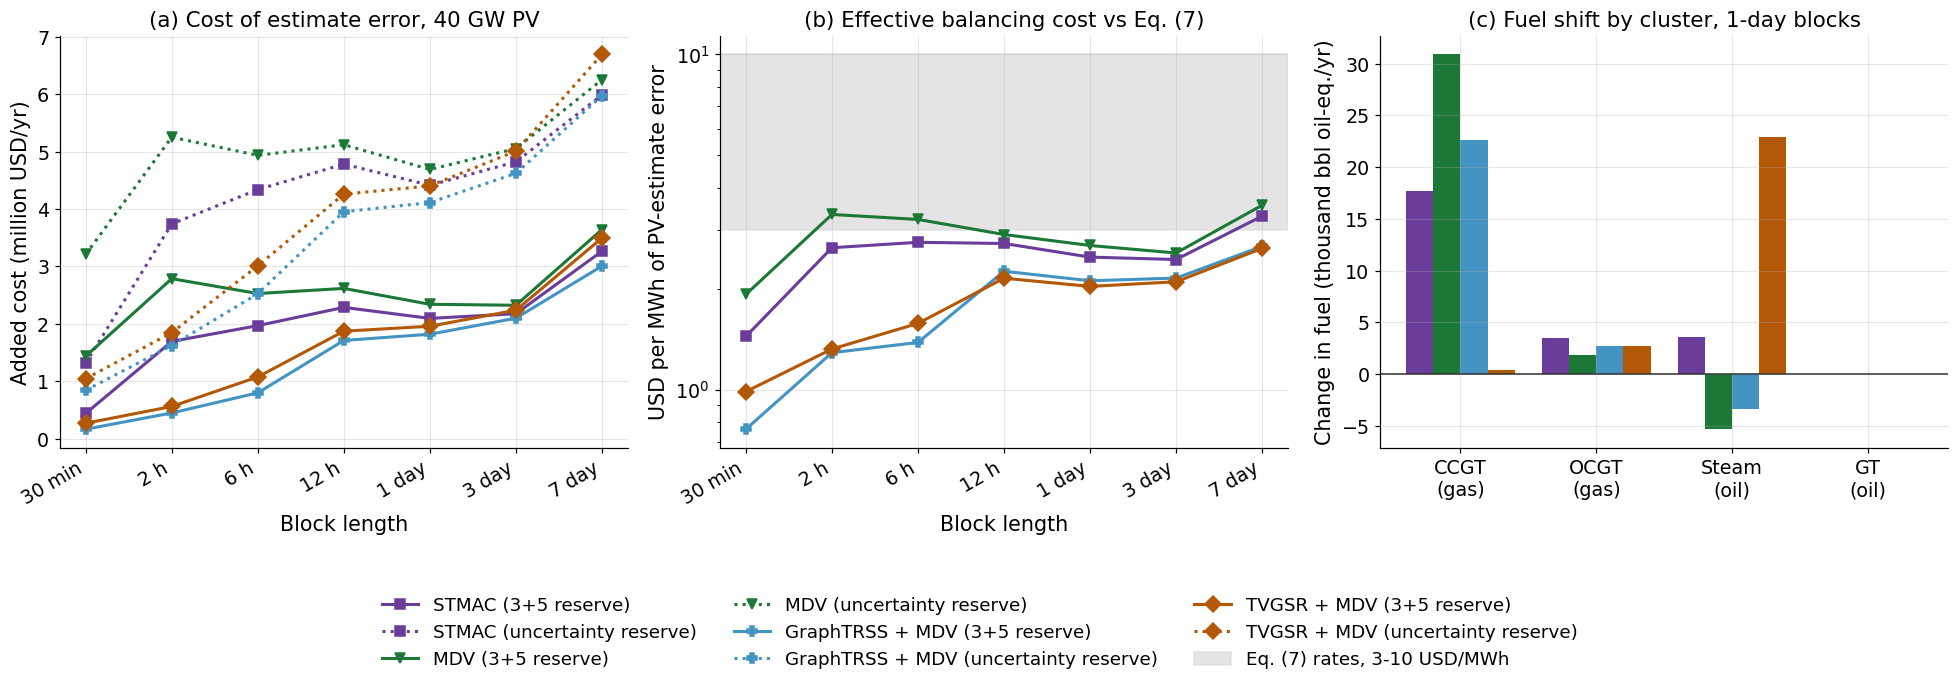

In [14]:
COL = {"stmac": "#6a3d9a", "mdv": "#1b7837", "graphtrss_mdv": "#4393c3", "tvgsr_mdv": "#b35806"}
MRK = {"stmac": "s", "mdv": "v", "graphtrss_mdv": "P", "tvgsr_mdv": "D"}
fig, axes = plt.subplots(1, 3, figsize=(18, 5.6))
x = np.arange(len(order))
ax = axes[0]
for k in MNAME:
    for res, ls in [("rule", "-"), ("uncertainty", ":")]:
        sub = main[(main.cap == 40.0) & (main.reserve == res) & (main.method == k)].set_index("label").loc[order]
        ax.plot(x, sub.d_cost_musd, marker=MRK[k], ls=ls, color=COL[k], lw=2, ms=7,
                label=f"{MNAME[k]}" + (" (3+5 reserve)" if res == "rule" else " (uncertainty reserve)"))
ax.set_xticks(x); ax.set_xticklabels(order, rotation=30, ha="right")
ax.set_xlabel("Block length"); ax.set_ylabel("Added cost (million USD/yr)")
ax.set_title("(a) Cost of estimate error, 40 GW PV")
ax = axes[1]
for k in MNAME:
    sub = main[(main.cap == 40.0) & (main.reserve == "rule") & (main.method == k)].set_index("label").loc[order]
    ax.plot(x, sub.eff_rate, marker=MRK[k], color=COL[k], lw=2, ms=7, label=MNAME[k])
ax.axhspan(3, 10, color="0.85", alpha=0.7, label="Eq. (7) rates, 3-10 USD/MWh")
ax.set_yscale("log")
ax.set_xticks(x); ax.set_xticklabels(order, rotation=30, ha="right")
ax.set_xlabel("Block length"); ax.set_ylabel("USD per MWh of PV-estimate error")
ax.set_title("(b) Effective balancing cost vs Eq. (7)")
ax = axes[2]
sub = main[(main.cap == 40.0) & (main.reserve == "rule") & (main.block_len == 288)].set_index("method")
wdt = 0.2
for j, k in enumerate(MNAME):
    vals = [sub.loc[k, f"d_fuel_mmbtu_{c}"] / uc.MMBTU_PER_BBL / 1000 for c in range(4)]
    ax.bar(np.arange(4) + (j - 1.5) * wdt, vals, wdt, color=COL[k], label=MNAME[k])
ax.axhline(0, color="0.2", lw=1)
ax.set_xticks(range(4)); ax.set_xticklabels(["CCGT\n(gas)", "OCGT\n(gas)", "Steam\n(oil)", "GT\n(oil)"])
ax.set_ylabel("Change in fuel (thousand bbl oil-eq./yr)")
ax.set_title("(c) Fuel shift by cluster, 1-day blocks")
h0, l0 = axes[0].get_legend_handles_labels(); h1, l1 = axes[1].get_legend_handles_labels()
fig.legend(h0 + h1[-1:], l0 + l1[-1:], loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.13))
fig.tight_layout(rect=(0, 0.08, 1, 1))
fig.savefig(RES / "E15_power_system_valuation.png")
plt.show()

In [15]:
print("PEMBACAAN GAMBAR E15")
print("=" * 88)
for k in MNAME:
    s = main[(main.cap == 40.0) & (main.reserve == "rule") & (main.method == k)].set_index("label").loc[order]
    print(f"- {MNAME[k]}: tambahan biaya {idn(s.d_cost_musd.min(), 3)} sampai {idn(s.d_cost_musd.max(), 3)} juta USD/tahun; "
          f"tarif efektif {idn(s.eff_rate.min(), 2)} sampai {idn(s.eff_rate.max(), 2)} USD/MWh.")
sub = main[(main.cap == 40.0) & (main.reserve == "rule") & (main.block_len == 288)].set_index("method")
for k in MNAME:
    v = [sub.loc[k, f"d_fuel_mmbtu_{c}"] / uc.MMBTU_PER_BBL / 1000 for c in range(4)]
    print(f"- Panel (c), {MNAME[k]}: CCGT {idn(v[0])}, OCGT {idn(v[1])}, uap {idn(v[2])}, GT {idn(v[3])} ribu bbl/tahun.")

PEMBACAAN GAMBAR E15
- STMAC: tambahan biaya 0,443 sampai 3,265 juta USD/tahun; tarif efektif 1,44 sampai 3,29 USD/MWh.
- MDV: tambahan biaya 1,439 sampai 3,643 juta USD/tahun; tarif efektif 1,93 sampai 3,55 USD/MWh.
- GraphTRSS + MDV: tambahan biaya 0,169 sampai 3,007 juta USD/tahun; tarif efektif 0,76 sampai 2,68 USD/MWh.
- TVGSR + MDV: tambahan biaya 0,272 sampai 3,496 juta USD/tahun; tarif efektif 0,99 sampai 2,64 USD/MWh.
- Panel (c), STMAC: CCGT 17,7, OCGT 3,5, uap 3,6, GT -0,0 ribu bbl/tahun.
- Panel (c), MDV: CCGT 30,9, OCGT 1,8, uap -5,3, GT 0,0 ribu bbl/tahun.
- Panel (c), GraphTRSS + MDV: CCGT 22,6, OCGT 2,7, uap -3,3, GT -0,0 ribu bbl/tahun.
- Panel (c), TVGSR + MDV: CCGT 0,4, OCGT 2,7, uap 22,9, GT 0,0 ribu bbl/tahun.


## 8. Skenario harga bahan bakar dan sensitivitas profil beban

Dengan harga bahan bakar seragam, biaya bahan bakar berbanding lurus dengan harga minyak, sedangkan biaya *start-up* tetap. Kita menskalakan komponen bahan bakar ke 96 USD/bbl (proyeksi EIA 2026) dan ke nilai kesejahteraan 6 dan 56 USD/bbl (Blazquez dkk., 2019). Sensitivitas profil beban memakai dua realisasi beban lain dengan $\sigma_0$ yang sama.

In [16]:
rows = []
for cap in CAPS:
    sub = main[(main.cap == cap) & (main.reserve == "rule")]
    for k in MNAME:
        s = sub[sub.method == k]
        fuel, start, voll = s.d_fuel_cost.mean(), s.d_start_cost.mean(), s.d_voll_cost.mean()
        for name, price in [("Brent 2025 (69)", 69.0), ("EIA 2026 (96)", 96.0), ("Kesejahteraan rendah (6)", 6.0),
                            ("Kesejahteraan tinggi (56)", 56.0)]:
            rows.append(dict(cap=cap, method=MNAME[k], scenario=name,
                             d_cost_musd=(fuel * price / BRENT_2025 + start + voll) / 1e6))
PRICE = pd.DataFrame(rows)
ru.atomic_csv(PRICE, RES / "E15_price_scenarios.csv")
print("Rata-rata tujuh blok, aturan 3+5 (juta USD/tahun)")
print(PRICE.pivot_table(index=["cap", "method"], columns="scenario", values="d_cost_musd").round(3).to_string())

SENS = R[(R.block_len == 288) & (R.cap == 40.0) & (R.reserve == "rule") & (R.seed == 0)]
SENS = SENS.pivot(index="method", columns="tag", values="d_cost_musd").rename(index=MNAME)
ru.atomic_csv(SENS.reset_index(), RES / "E15_load_sensitivity.csv")
print("\nSensitivitas profil beban, 40 GW, blok 1 hari (juta USD/tahun)")
print(SENS.round(3).to_string())

Rata-rata tujuh blok, aturan 3+5 (juta USD/tahun)
scenario              Brent 2025 (69)  EIA 2026 (96)  Kesejahteraan rendah (6)  Kesejahteraan tinggi (56)
cap  method                                                                                              
19.3 GraphTRSS + MDV            0.193          0.317                    -0.097                      0.133
     MDV                        0.364          0.501                     0.044                      0.298
     STMAC                      0.275          0.393                     0.002                      0.219
     TVGSR + MDV                0.221          0.343                    -0.063                      0.163
40.0 GraphTRSS + MDV            1.437          1.875                     0.417                      1.227
     MDV                        2.526          3.463                     0.340                      2.075
     STMAC                      1.991          2.681                     0.381                      1.

In [17]:
print("INTERPRETASI SKENARIO DAN SENSITIVITAS")
print("=" * 88)
p = PRICE.pivot_table(index=["cap", "method"], columns="scenario", values="d_cost_musd")
for cap in CAPS:
    q = p.loc[cap]
    print(f"- PV {idn(cap)} GW: pada 96 USD/bbl tambahan biaya berkisar {idn(q['EIA 2026 (96)'].min(), 3)} sampai "
          f"{idn(q['EIA 2026 (96)'].max(), 3)} juta USD/tahun; pada nilai kesejahteraan 6 sampai 56 USD/bbl "
          f"{idn(q['Kesejahteraan rendah (6)'].min(), 3)} sampai {idn(q['Kesejahteraan tinggi (56)'].max(), 3)}.")
spread = SENS.max(axis=1) - SENS.min(axis=1)
print(f"- Antarrealisasi profil beban, biaya blok 1 hari pada 40 GW berubah paling banyak {idn(spread.max(), 3)} juta USD/tahun; "
      f"urutan metode {'sama' if (SENS.rank().nunique(axis=1) == 1).all() else 'berubah'} di semua realisasi.")

INTERPRETASI SKENARIO DAN SENSITIVITAS
- PV 19,3 GW: pada 96 USD/bbl tambahan biaya berkisar 0,317 sampai 0,501 juta USD/tahun; pada nilai kesejahteraan 6 sampai 56 USD/bbl -0,097 sampai 0,298.
- PV 40,0 GW: pada 96 USD/bbl tambahan biaya berkisar 1,875 sampai 3,463 juta USD/tahun; pada nilai kesejahteraan 6 sampai 56 USD/bbl 0,332 sampai 2,075.
- Antarrealisasi profil beban, biaya blok 1 hari pada 40 GW berubah paling banyak 0,565 juta USD/tahun; urutan metode sama di semua realisasi.


## 9. Ringkasan temuan

Sel terakhir merangkum angka utama dan menyimpannya ke `E15_summary_numbers.csv`. Ringkasan dihitung ulang dari hasil aktual setiap kali notebook dijalankan.

In [18]:
NUM = []
for _, r in R.iterrows():
    NUM.append(dict(key=r.key, d_cost_musd=r.d_cost_musd, d_fuel_kbbl=r.d_fuel_kbbl, eff_rate=r.eff_rate,
                    eq7_3_musd=r.eq7_3_musd, eq7_10_musd=r.eq7_10_musd, abs_err_gwh=r.abs_err_mwh / 1000))
ru.atomic_csv(pd.DataFrame(NUM), RES / "E15_summary_numbers.csv")
print("RINGKASAN E15")
print("=" * 88)
print(f"1. Profil beban 2025 estimasi: puncak {idn(Ls.max(), 2)} GW, energi {idn(Ls.sum() / 1000)} TWh, faktor beban "
      f"{idn(Ls.mean() / Ls.max(), 3)}, durasi 3 GW teratas {lm.top_hours(LOAD_GW)} jam (ECRA 2019: 76 jam).")
print(f"2. Validasi sistem (12,3 GW PV): efisiensi termal {idn(sv.loc['Efisiensi rata-rata termal (%)', 'model'], 1)}% "
      f"(SE 38,15%), bahan bakar cair {idn(sv.loc['Konsumsi bahan bakar cair (ribu b/d setara minyak)', 'model'], 0)} ribu b/d "
      f"(MEES 991 ribu b/d).")
for cap in CAPS:
    sub = main[(main.cap == cap) & (main.reserve == "rule")]
    avg = sub.groupby("method")[["d_cost_musd", "eq7_3_musd", "eq7_10_musd", "d_fuel_kbbl"]].mean()
    print(f"3. PV {idn(cap)} GW, aturan 3+5, rata-rata tujuh blok: " +
          "; ".join(f"{MNAME[k]} {idn(avg.loc[k, 'd_cost_musd'], 3)} juta USD ({idn(avg.loc[k, 'd_fuel_kbbl'], 1)} ribu bbl)"
                    for k in avg.index) + " per tahun.")
    print(f"   Persamaan (7) dengan RMSE yang sama: {idn(avg.eq7_3_musd.min(), 2)} sampai {idn(avg.eq7_10_musd.max(), 2)} juta USD/tahun.")
er_all = main[main.reserve == "rule"].eff_rate
print(f"4. Tarif efektif penyeimbangan: median {idn(er_all.median(), 2)} USD/MWh (rentang {idn(er_all.min(), 2)} sampai "
      f"{idn(er_all.max(), 2)}), terhadap 3 sampai 10 USD/MWh pada Persamaan (7).")
s40 = main[(main.cap == 40.0) & (main.reserve == "rule")].pivot(index="label", columns="method", values="d_cost_musd").loc[order]
d = s40["stmac"] - s40["graphtrss_mdv"]
print(f"5. STMAC dikurangi GraphTRSS + MDV pada 40 GW: {idn(d.min(), 3)} sampai {idn(d.max(), 3)} juta USD/tahun per blok "
      "(negatif berarti STMAC lebih murah).")

RINGKASAN E15
1. Profil beban 2025 estimasi: puncak 77,08 GW, energi 428,7 TWh, faktor beban 0,635, durasi 3 GW teratas 95 jam (ECRA 2019: 76 jam).
2. Validasi sistem (12,3 GW PV): efisiensi termal 41,7% (SE 38,15%), bahan bakar cair 770 ribu b/d (MEES 991 ribu b/d).
3. PV 19,3 GW, aturan 3+5, rata-rata tujuh blok: GraphTRSS + MDV 0,193 juta USD (4,6 ribu bbl); MDV 0,364 juta USD (5,1 ribu bbl); STMAC 0,275 juta USD (4,3 ribu bbl); TVGSR + MDV 0,221 juta USD (4,5 ribu bbl) per tahun.
   Persamaan (7) dengan RMSE yang sama: 3,27 sampai 13,75 juta USD/tahun.
3. PV 40,0 GW, aturan 3+5, rata-rata tujuh blok: GraphTRSS + MDV 1,437 juta USD (16,2 ribu bbl); MDV 2,526 juta USD (34,7 ribu bbl); STMAC 1,991 juta USD (25,6 ribu bbl); TVGSR + MDV 1,640 juta USD (20,8 ribu bbl) per tahun.
   Persamaan (7) dengan RMSE yang sama: 6,77 sampai 28,49 juta USD/tahun.
4. Tarif efektif penyeimbangan: median 1,11 USD/MWh (rentang 0,28 sampai 3,55), terhadap 3 sampai 10 USD/MWh pada Persamaan (7).
5. STMAC 